# KhabarNazar: fine-tuning XLM-RoBERTa for Roman Urdu fake news detection

**Task:** binary classification of a Roman Urdu news article as `real` (0) or `fake` (1).
**Model:** `xlm-roberta-base` (278M parameters, pre-trained on 100 languages including Urdu).
**Data:** 8,267 articles from Bend the Truth, FIRE 2021, Ax-to-Grind and Hook and Bait, transliterated to Roman Urdu. Split 80/10/10 in `01_make_splits.ipynb`.

### Before you run: Google Colab
1. In Colab: **Runtime → Change runtime type → T4 GPU → Save**.
2. Put `train.csv`, `val.csv`, `test.csv` in Google Drive at `MyDrive/KhabarNazar_text/data/splits/`.
3. **Runtime → Run all.** Allow Drive access when asked. Training takes about 30 to 45 minutes on a T4.

Outputs (in `MyDrive/KhabarNazar_text/`): the trained model in `model/`, and metrics, plots and predictions in `outputs/`.

### Before you run: your own GPU computer
1. Set up the environment once (see "Running on a GPU computer" in `text_module/README.md`).
2. Keep the split files in `text_module/data/splits/` (they are already there in the zip).
3. Open this notebook from `text_module/notebooks/` in Jupyter or VS Code and run all cells. Nothing else changes: the notebook finds the local folders by itself, and it picks a batch size that fits the GPU.

Outputs: the model in `text_module/model/` (ignored by git) and results in `text_module/outputs/`.

## 1. Setup

In [4]:
# Colab already has torch, transformers, scikit-learn, pandas and matplotlib.
# On your own computer this also works, it installs into the notebook's environment.
%pip install -q datasets

In [5]:
import os, json, random
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import transformers
import matplotlib.pyplot as plt
from datasets import Dataset
from sklearn.metrics import (accuracy_score, f1_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding,
                          TrainingArguments, Trainer, EarlyStoppingCallback, set_seed)

print("torch", torch.__version__, "| transformers", transformers.__version__)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE! Colab: Runtime -> Change runtime type -> T4 GPU. Own computer: install the CUDA build of PyTorch.")

torch 2.11.0+cu130 | transformers 5.20.1
GPU: Tesla T4


In [6]:
# Mount Google Drive (in Colab). Outside Colab, the repo folders are used instead.
try:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = Path("/content/drive/MyDrive/KhabarNazar_text")
except ImportError:
    BASE = Path("..")

SPLIT_DIR   = BASE / "data" / "splits"
MODEL_DIR   = BASE / "model"            # final model (about 1.1 GB, never goes on GitHub)
RESULTS_DIR = BASE / "outputs"          # small files, these DO go on GitHub
CHECKPOINTS = Path("/content/checkpoints") if BASE.as_posix().startswith("/content") else Path("../checkpoints")
for p in [MODEL_DIR, RESULTS_DIR, CHECKPOINTS]:
    p.mkdir(parents=True, exist_ok=True)
print("reading splits from", SPLIT_DIR, "->", sorted(os.listdir(SPLIT_DIR)))

Mounted at /content/drive
reading splits from /content/drive/MyDrive/KhabarNazar_text/data/splits -> ['test.csv', 'train.csv', 'val.csv']


## 2. Settings

| Setting | Value | Why |
|---|---|---|
| `MAX_LEN` | 512 | XLM-R's limit. Headlines are about 40 tokens; long articles are cut at 512. |
| batch × accumulation | always 16 articles per update | chosen from GPU memory: 8 × 2 on a T4 (15 GB) or smaller cards, 16 × 1 on 20 GB or more. The effective batch stays 16, so Colab and GPU-computer runs are comparable. |
| learning rate | 2e-5 | standard for XLM-R; higher rates can make it predict one class only |
| epochs | up to 5 | early stopping halts if validation macro-F1 stops improving for 2 epochs |

In [7]:
MODEL_NAME = "xlm-roberta-base"
MAX_LEN = 512
EFFECTIVE_BATCH = 16
gpu_gb = torch.cuda.get_device_properties(0).total_memory / 1e9 if torch.cuda.is_available() else 0
if gpu_gb >= 20:
    BATCH_SIZE = 16
elif gpu_gb >= 12:
    BATCH_SIZE = 8
else:
    BATCH_SIZE = 4                     # e.g. an 8 GB card; if it still runs out of memory, use 2
GRAD_ACCUM = EFFECTIVE_BATCH // BATCH_SIZE
# bf16 on newer GPUs (RTX 30xx/40xx, A100), fp16 on older ones (T4)
USE_BF16 = torch.cuda.is_available() and torch.cuda.is_bf16_supported()
USE_FP16 = torch.cuda.is_available() and not USE_BF16
print(f"GPU memory {gpu_gb:.0f} GB -> batch {BATCH_SIZE} x accumulation {GRAD_ACCUM}, bf16={USE_BF16}, fp16={USE_FP16}")
LEARNING_RATE = 2e-5
EPOCHS = 5
WARMUP_FRACTION = 0.1
WEIGHT_DECAY = 0.01
SEED = 42

LABEL2ID = {"real": 0, "fake": 1}
ID2LABEL = {0: "real", 1: "fake"}

random.seed(SEED); np.random.seed(SEED); set_seed(SEED)

GPU memory 16 GB -> batch 8 x accumulation 2, bf16=True, fp16=False


## 3. Load the data

In [8]:
train_df = pd.read_csv(SPLIT_DIR / "train.csv")
val_df   = pd.read_csv(SPLIT_DIR / "val.csv")
test_df  = pd.read_csv(SPLIT_DIR / "test.csv")

for d in (train_df, val_df, test_df):
    d["labels"] = d["label"].map(LABEL2ID)
    assert d["labels"].notna().all() and d["roman_text"].notna().all()

# leakage check: no article id or near-duplicate group in two splits
assert not set(train_df.group_id) & set(test_df.group_id)
assert not set(train_df.group_id) & set(val_df.group_id)
assert not set(val_df.group_id) & set(test_df.group_id)

print(len(train_df), len(val_df), len(test_df))
pd.crosstab(test_df.source_dataset, test_df.label)

6615 826 826


label,fake,real
source_dataset,,
ax_to_grind,124,123
bend_the_truth,40,49
fire,25,45
hook_and_bait,210,210


## 4. Baseline: TF-IDF + logistic regression

A simple, fast model to compare against. If XLM-RoBERTa can't beat this, something is wrong.

In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline, make_union

baseline = make_pipeline(
    make_union(TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
               TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True)),
    LogisticRegression(C=4, max_iter=3000))
baseline.fit(train_df.roman_text, train_df.labels)
test_df["baseline_pred"] = baseline.predict(test_df.roman_text)

def scores(y_true, y_pred):
    return {"accuracy": round(accuracy_score(y_true, y_pred), 4),
            "f1_macro": round(f1_score(y_true, y_pred, average="macro"), 4),
            "n": int(len(y_true))}

baseline_results = {"all": scores(test_df.labels, test_df.baseline_pred)}
for src, g in test_df.groupby("source_dataset"):
    baseline_results[src] = scores(g.labels, g.baseline_pred)
pd.DataFrame(baseline_results).T

,accuracy,f1_macro,n
all,0.8208,0.8204,826.0
ax_to_grind,0.7935,0.7934,247.0
bend_the_truth,0.6629,0.6577,89.0
fire,0.6714,0.6234,70.0
hook_and_bait,0.8952,0.8952,420.0


## 5. Tokenize

In [10]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# how many articles are longer than MAX_LEN tokens?
lengths = train_df.roman_text.map(lambda t: len(tokenizer(t)["input_ids"]))
train_df["n_tokens"] = lengths
print(train_df.groupby("source_dataset").n_tokens.describe(percentiles=[.5, .9]).round(0))
print(f"truncated at {MAX_LEN}: {(lengths > MAX_LEN).mean():.1%} of training articles")

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (672 > 512). Running this sequence through the model will result in indexing errors


                 count   mean    std    min    50%     90%     max
source_dataset                                                    
ax_to_grind     1980.0   57.0   30.0   23.0   47.0    92.0   298.0
bend_the_truth   717.0  521.0  412.0  101.0  389.0  1060.0  3552.0
fire             558.0  458.0  459.0   72.0  312.0   868.0  3990.0
hook_and_bait   3360.0   49.0   32.0   24.0   44.0    64.0   708.0
truncated at 512: 5.4% of training articles


In [11]:
def to_dataset(d):
    ds = Dataset.from_pandas(d[["roman_text", "labels"]].reset_index(drop=True))
    return ds.map(lambda b: tokenizer(b["roman_text"], truncation=True, max_length=MAX_LEN),
                  batched=True, remove_columns=["roman_text"])

train_ds, val_ds, test_ds = to_dataset(train_df), to_dataset(val_df), to_dataset(test_df)
collator = DataCollatorWithPadding(tokenizer)   # pads each batch only to its longest article
train_ds

Map:   0%|          | 0/6615 [00:00<?, ? examples/s]

Map:   0%|          | 0/826 [00:00<?, ? examples/s]

Map:   0%|          | 0/826 [00:00<?, ? examples/s]

Dataset({
    features: ['labels', 'input_ids', 'attention_mask'],
    num_rows: 6615
})

## 6. Model and training

In [12]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=2, id2label=ID2LABEL, label2id=LABEL2ID)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    p, r, f, _ = precision_recall_fscore_support(labels, preds, average="binary", pos_label=1, zero_division=0)
    return {"accuracy": accuracy_score(labels, preds),
            "f1_macro": f1_score(labels, preds, average="macro"),
            "precision_fake": p, "recall_fake": r, "f1_fake": f}

steps_per_epoch = int(np.ceil(len(train_ds) / (BATCH_SIZE * GRAD_ACCUM)))
args = TrainingArguments(
    output_dir=str(CHECKPOINTS),
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=32,
    gradient_accumulation_steps=GRAD_ACCUM,
    learning_rate=LEARNING_RATE,
    num_train_epochs=EPOCHS,
    warmup_steps=int(WARMUP_FRACTION * steps_per_epoch * EPOCHS),
    weight_decay=WEIGHT_DECAY,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    greater_is_better=True,
    fp16=USE_FP16,
    bf16=USE_BF16,
    logging_steps=50,
    report_to="none",
    seed=SEED,
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    data_collator=collator,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
)

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.weight        | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Training prints a table after each epoch. **Watch `f1_macro` on validation.** It should climb above the baseline within 1 to 2 epochs.

If it stays at about **0.33** (the model predicts one class for everything), the run collapsed. Restart the runtime, set `LEARNING_RATE = 1e-5` or `SEED = 7`, and run all again.

In [13]:
train_output = trainer.train()
train_output

Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro,Precision Fake,Recall Fake,F1 Fake
1,1.145027,0.469654,0.795400,0.794278,0.811989,0.748744,0.779085
2,0.899223,0.442944,0.811138,0.811098,0.775000,0.856784,0.813842
3,0.723284,0.448070,0.818402,0.818295,0.803922,0.824121,0.813896
4,0.671345,0.493695,0.825666,0.825296,0.825641,0.809045,0.817259
5,0.378617,0.521906,0.840194,0.840134,0.822816,0.851759,0.837037


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=2070, training_loss=0.7998737464204503, metrics={'train_runtime': 3465.0891, 'train_samples_per_second': 9.545, 'train_steps_per_second': 0.597, 'total_flos': 6100004221347180.0, 'train_loss': 0.7998737464204503, 'epoch': 5.0})

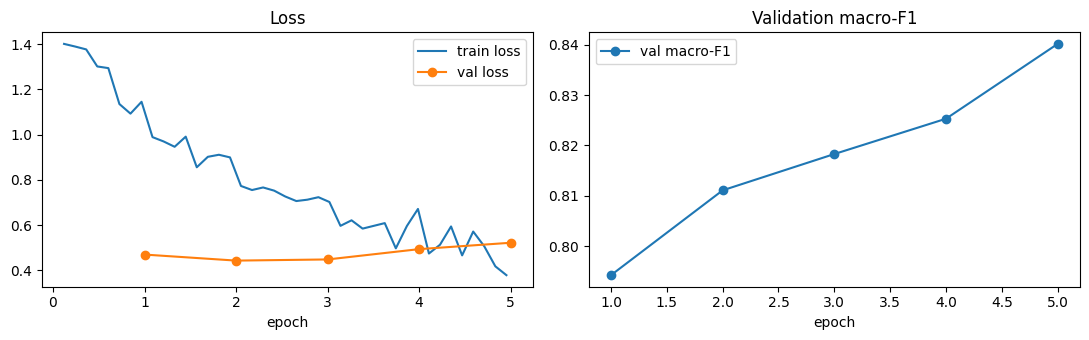

In [14]:
# training curve
hist = pd.DataFrame(trainer.state.log_history)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
hist.dropna(subset=["loss"]).plot(x="epoch", y="loss", ax=ax[0], label="train loss")
hist.dropna(subset=["eval_loss"]).plot(x="epoch", y="eval_loss", ax=ax[0], label="val loss", marker="o")
hist.dropna(subset=["eval_f1_macro"]).plot(x="epoch", y="eval_f1_macro", ax=ax[1], marker="o", label="val macro-F1")
ax[0].set_title("Loss"); ax[1].set_title("Validation macro-F1")
plt.tight_layout(); plt.savefig(RESULTS_DIR / "training_curve.png", dpi=150); plt.show()
hist.to_csv(RESULTS_DIR / "training_log.csv", index=False)

## 7. Evaluate on the test set

The test set was not used for any decision during training, so this is the number to report.

In [15]:
pred = trainer.predict(test_ds)
probs = torch.softmax(torch.tensor(pred.predictions), dim=-1)[:, 1].numpy()
test_df["pred"] = pred.predictions.argmax(-1)
test_df["prob_fake"] = probs.round(4)

print(classification_report(test_df.labels, test_df.pred, target_names=["real", "fake"], digits=4))

results = {"all": scores(test_df.labels, test_df.pred)}
for src, g in test_df.groupby("source_dataset"):
    results[src] = scores(g.labels, g.pred)

table = pd.DataFrame({
    "XLM-R accuracy": {k: v["accuracy"] for k, v in results.items()},
    "XLM-R macro-F1": {k: v["f1_macro"] for k, v in results.items()},
    "baseline macro-F1": {k: v["f1_macro"] for k, v in baseline_results.items()},
    "n": {k: v["n"] for k, v in results.items()},
})
table

              precision    recall  f1-score   support

        real     0.8533    0.8173    0.8349       427
        fake     0.8129    0.8496    0.8309       399

    accuracy                         0.8329       826
   macro avg     0.8331    0.8335    0.8329       826
weighted avg     0.8338    0.8329    0.8330       826



,XLM-R accuracy,XLM-R macro-F1,baseline macro-F1,n
all,0.8329,0.8329,0.8204,826
ax_to_grind,0.8381,0.8381,0.7934,247
bend_the_truth,0.6629,0.6619,0.6577,89
fire,0.7571,0.7216,0.6234,70
hook_and_bait,0.8786,0.8783,0.8952,420


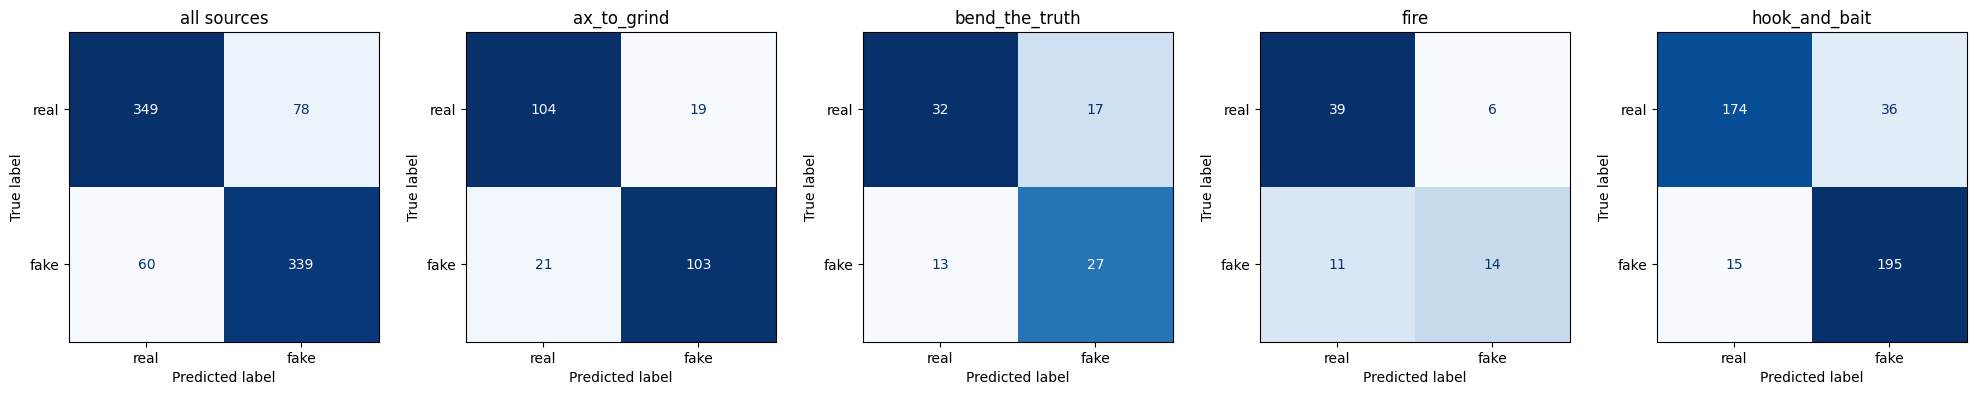

In [16]:
fig, axes = plt.subplots(1, 5, figsize=(20, 3.8))
groups = [("all sources", test_df)] + list(test_df.groupby("source_dataset"))
for ax, (name, g) in zip(axes, groups):
    cm = confusion_matrix(g.labels, g.pred, labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=["real", "fake"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)
plt.tight_layout(); plt.savefig(RESULTS_DIR / "confusion_matrices.png", dpi=150); plt.show()

In [17]:
# save results: these small files go into the GitHub repo
val_metrics = trainer.evaluate(val_ds)
summary = {
    "model": MODEL_NAME,
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
    "settings": {"max_len": MAX_LEN, "batch_size": BATCH_SIZE, "grad_accum": GRAD_ACCUM,
                 "learning_rate": LEARNING_RATE, "max_epochs": EPOCHS, "seed": SEED},
    "epochs_trained": round(trainer.state.epoch, 2),
    "best_checkpoint": trainer.state.best_model_checkpoint,
    "validation": {k: round(float(v), 4) for k, v in val_metrics.items() if isinstance(v, (int, float))},
    "test_xlmr": results,
    "test_baseline_tfidf_lr": baseline_results,
    "versions": {"torch": torch.__version__, "transformers": transformers.__version__},
}
(RESULTS_DIR / "metrics.json").write_text(json.dumps(summary, indent=2))
table.to_csv(RESULTS_DIR / "results_table.csv")
# predictions by id only, no article text (the text cannot be redistributed)
test_df[["id", "source_dataset", "label", "pred", "prob_fake"]].assign(
    pred=lambda d: d.pred.map(ID2LABEL)).to_csv(RESULTS_DIR / "test_predictions.csv", index=False)
print(json.dumps(summary["test_xlmr"], indent=2))

Training Loss,Validation Loss,Epoch,Accuracy,F1 Macro,Precision Fake,Recall Fake,F1 Fake
0.378617,0.521906,5,0.840194,0.840134,0.822816,0.851759,0.837037


{
  "all": {
    "accuracy": 0.8329,
    "f1_macro": 0.8329,
    "n": 826
  },
  "ax_to_grind": {
    "accuracy": 0.8381,
    "f1_macro": 0.8381,
    "n": 247
  },
  "bend_the_truth": {
    "accuracy": 0.6629,
    "f1_macro": 0.6619,
    "n": 89
  },
  "fire": {
    "accuracy": 0.7571,
    "f1_macro": 0.7216,
    "n": 70
  },
  "hook_and_bait": {
    "accuracy": 0.8786,
    "f1_macro": 0.8783,
    "n": 420
  }
}


## 8. Error analysis

Read some mistakes. Patterns here are useful material for the report's discussion section.

In [18]:
wrong = test_df[test_df.pred != test_df.labels]
print(len(wrong), "wrong out of", len(test_df))
print(wrong.source_dataset.value_counts())
pd.set_option("display.max_colwidth", 200)
wrong.sample(min(10, len(wrong)), random_state=SEED)[["source_dataset", "label", "prob_fake", "roman_text"]]

138 wrong out of 826
source_dataset
hook_and_bait     51
ax_to_grind       40
bend_the_truth    30
fire              17
Name: count, dtype: int64


,source_dataset,label,prob_fake,roman_text
485,hook_and_bait,real,0.9598,Hyderabad ke hawai adde se pakre gaye aadmi ke zer-e-jame mein chhupaya gaya ₹39.6 lakh maliyat ka sona zabt
586,ax_to_grind,fake,0.0373,10 sala naujawan Bharti larki Anitha ki shadi apne chacha Shiv Nath Chaturvedi se ho rahi hai jin ki umar 40 saal hai
68,hook_and_bait,fake,0.0066,Insaniyat ke khilaf jaraim mein ek azeem jury trial shuru hota hai jis mein ek man gharat coronavirus wabai bimari shamil hai.
131,bend_the_truth,real,0.9667,Google ka kehna hai ke Chrome browser ka version 71 sarifeen ko gumrah kar ke ishtihar dikhane wali tamam sites ke ishtihar block karega Google ke mutabiq is tarah ke aadhe se zyada ishtihar maujo...
353,ax_to_grind,real,0.9748,"Jumeraat ko Pakistani media reports mein daawa kiya gaya hai ke Pakistan ke aqwam-e-muttahida ke mustaqil numainde (PR) ne UNSC ko ek tehreeri guzarish bheji hai jis mein RSS samait ""mutashaddid i..."
369,hook_and_bait,real,0.9965,CCTV footage ki bunyad par mushtaba qarar diya gaya shakhs jo mubayyana police tashaddud se mara gaya
363,hook_and_bait,real,0.9873,Video mein Pakistan International Airlines ke pilots ko yeh janne ki koshish karte hue suna ja sakta hai ke un ke tayyare ke upar namaloom flying object kya hai.
725,bend_the_truth,real,0.9115,Mumbai 12 December (agency) Bollywood adakara Nargis Fakhri ne Anushka Sharma ki tareef ki hai Nargis Fakhri jald hi horror film Amavas mein nazar aayengi unhon ne Anushka Sharma ki tareef ki hai ...
617,fire,fake,0.1403,Jannat Mirza ki aisi video samne aa gayi ke social media sarifeen ne un ko 'lalchi' qarar de diya Faisalabad (Monitoring Desk) TikToker Jannat Mirza aur un ki behan Alishba Anjum Pakistan ki maqbo...
398,hook_and_bait,real,0.9951,Patiala SP ne kaha ke Muslim aksariyati ilaqon mein Hinduon par hamla nahi kiya jata hai aur ise shikast nahi di jati hai.


In [19]:
# Length check: can word count alone predict the label? (FIRE has a real/fake length gap)
from sklearn.linear_model import LogisticRegression as LR
for src in ["fire", "bend_the_truth"]:
    tr = train_df[train_df.source_dataset == src]; te = test_df[test_df.source_dataset == src]
    X = lambda d: np.log1p(d.roman_text.str.split().str.len()).to_frame()
    clf = LR().fit(X(tr), tr.labels)
    print(f"{src}: macro-F1 from length alone = {f1_score(te.labels, clf.predict(X(te)), average='macro'):.3f}")

fire: macro-F1 from length alone = 0.589
bend_the_truth: macro-F1 from length alone = 0.429


## 9. Save the model and try it

In [20]:
trainer.save_model(str(MODEL_DIR))
tokenizer.save_pretrained(str(MODEL_DIR))
print("saved to", MODEL_DIR, "->", sorted(os.listdir(MODEL_DIR)))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

saved to /content/drive/MyDrive/KhabarNazar_text/model -> ['config.json', 'model.safetensors', 'tokenizer.json', 'tokenizer_config.json', 'training_args.bin']


In [21]:
from transformers import pipeline
clf = pipeline("text-classification", model=str(MODEL_DIR), tokenizer=str(MODEL_DIR),
               device=0 if torch.cuda.is_available() else -1)

examples = [
    "Qaumi cricket team ne aaj Lahore mein practice session mein hissa liya.",
    "Hukumat ne elaan kiya hai ke kal se tamam schools hamesha ke liye band kar diye jayenge.",
]
for text, out in zip(examples, clf(examples, truncation=True, max_length=MAX_LEN)):
    print(f"{out['label']:>5}  {out['score']:.2f}  {text}")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

 real  0.99  Qaumi cricket team ne aaj Lahore mein practice session mein hissa liya.
 real  0.77  Hukumat ne elaan kiya hai ke kal se tamam schools hamesha ke liye band kar diye jayenge.


## 10. (Optional) Upload the model to Hugging Face

GitHub can't hold a 1.1 GB model (its file limit is 100 MB). A **private** Hugging Face repo is the usual place. Make an account at huggingface.co, create a *write* token (Settings → Access Tokens), then uncomment and run the cell below. Put the model link in the README.

In [22]:
# from huggingface_hub import notebook_login
# notebook_login()
# HF_REPO = "your-hf-username/khabarnazar-xlmr-roman-urdu"
# model = AutoModelForSequenceClassification.from_pretrained(str(MODEL_DIR))
# model.push_to_hub(HF_REPO, private=True)
# tokenizer.push_to_hub(HF_REPO, private=True)